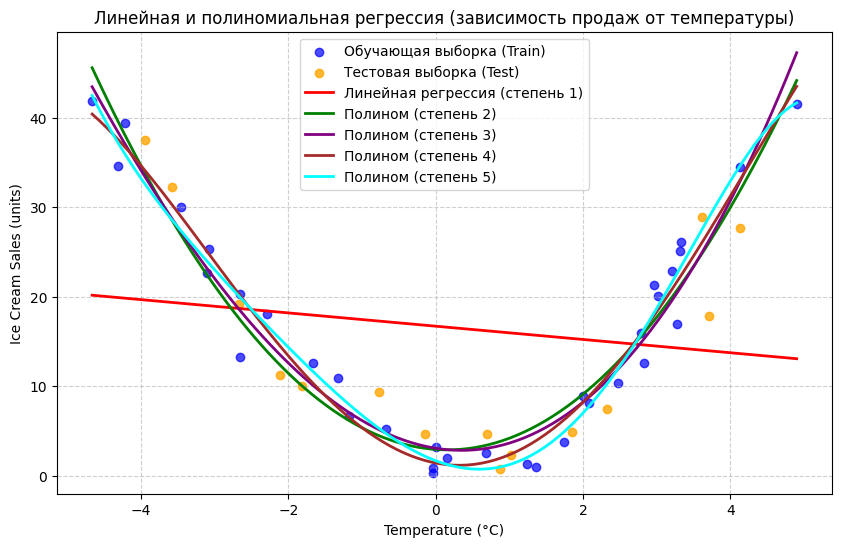


Сводная таблица метрик качества моделей:
                        Модель  MSE (Test)  R2 (Test)  MAPE (Test)  MSE (Train)  R2 (Train)  MAPE (Train)
Линейная регрессия (степень 1)    131.0803     0.0135       2.5279     148.5664      0.0266        3.7565
           Полином (степень 2)     13.3603     0.8995       0.5462       9.1358      0.9401        0.7008
           Полином (степень 3)     13.1344     0.9012       0.4820       8.2027      0.9463        0.6577
           Полином (степень 4)     14.8049     0.8886       0.3871       6.1323      0.9598        0.4175
           Полином (степень 5)     18.7660     0.8588       0.3252       5.0620      0.9668        0.3686


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

df = pd.read_csv('lab2_2_DS.csv')
X = df[['Temperature (°C)']].values
y = df['Ice Cream Sales (units)'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

degrees = [1, 2, 3, 4, 5]
colors = ['red', 'green', 'purple', 'brown', 'cyan']
results = []

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', label='Обучающая выборка (Train)', alpha=0.7)
plt.scatter(X_test, y_test, color='orange', label='Тестовая выборка (Test)', alpha=0.8)

X_grid = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

for deg, col in zip(degrees, colors):
    if deg == 1:
        model = LinearRegression()
        model.fit(X_train, y_train)
        y_pred_train = model.predict(X_train)
        y_pred_test = model.predict(X_test)
        y_grid = model.predict(X_grid)
        name = "Линейная регрессия (степень 1)"
    else:
        poly = PolynomialFeatures(degree=deg)
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)
        X_grid_poly = poly.transform(X_grid)
        
        model = LinearRegression()
        model.fit(X_train_poly, y_train)
        y_pred_train = model.predict(X_train_poly)
        y_pred_test = model.predict(X_test_poly)
        y_grid = model.predict(X_grid_poly)
        name = f"Полином (степень {deg})"
        
    mse_test = mean_squared_error(y_test, y_pred_test)
    r2_test = r2_score(y_test, y_pred_test)
    mape_test = mean_absolute_percentage_error(y_test, y_pred_test)
    
    mse_train = mean_squared_error(y_train, y_pred_train)
    r2_train = r2_score(y_train, y_pred_train)
    mape_train = mean_absolute_percentage_error(y_train, y_pred_train)
    
    results.append({
        'Модель': name,
        'MSE (Test)': round(mse_test, 4),
        'R2 (Test)': round(r2_test, 4),
        'MAPE (Test)': round(mape_test, 4),
        'MSE (Train)': round(mse_train, 4),
        'R2 (Train)': round(r2_train, 4),
        'MAPE (Train)': round(mape_train, 4)
    })
    
    plt.plot(X_grid, y_grid, color=col, linewidth=2, label=name)

plt.title('Линейная и полиномиальная регрессия (зависимость продаж от температуры)')
plt.xlabel('Temperature (°C)')
plt.ylabel('Ice Cream Sales (units)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('lab2_2_plot.png', dpi=150, bbox_inches='tight')
plt.show()

metrics_df = pd.DataFrame(results)
print("\nСводная таблица метрик качества моделей:")
print(metrics_df.to_string(index=False))